**Name:** Ishan Kulkarni
**Branch:** CSSE-B
**Roll no.:** 32

# PAS Home Assignment 3

## Aim
A healthcare
organization has conducted a survey to study patient satisfaction across
different hospitals and age groups. Using Python, analyze the survey data by
selecting appropriate samples, estimating population parameters using
confidence intervals, performing suitable hypothesis tests and one-way ANOVA
wherever applicable, interpreting the statistical significance of the results
using p-values, and preparing a report that justifies whether the observed
differences are statistically significant and supports the conclusions with
appropriate statistical evidence.

> I recommend to check the notebook from Github to get the latest version: [Github](https://github.com/ishanKulkarni13/PAS_college/blob/main/ha-3/ha-3.ipynb)

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Loading the Dataset

In [2]:
df = pd.read_csv('PAS-HA_3-Probability_Statistics_Datasets.csv')
df.head()

,Patient_ID,Hospital,Age_Group,Satisfaction_Score
0,1,C,18-30,4.0
1,2,A,60+,4.1
2,3,B,31-45,3.5
3,4,B,60+,3.1
4,5,A,18-30,4.0


## Understanding the Dataset

In [3]:
df.shape

(120, 4)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Patient_ID          120 non-null    int64  
 1   Hospital            120 non-null    str    
 2   Age_Group           120 non-null    str    
 3   Satisfaction_Score  120 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 3.9 KB


## Data Cleaning

In [5]:
df.isnull().sum()

Patient_ID            0
Hospital              0
Age_Group             0
Satisfaction_Score    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
print(df['Hospital'].value_counts())
print()
print(df['Age_Group'].value_counts())

Hospital
C    44
B    42
A    34
Name: count, dtype: int64

Age_Group
60+      37
18-30    30
46-60    27
31-45    26
Name: count, dtype: int64


No missing values and no duplicate rows, and the categories look clean (3 hospitals, 4 age groups), so nothing needs to be fixed. Satisfaction scores are between 2.4 and 5, which is fine for a 1 to 5 scale.

**Variables**

- **Patient_ID** - just an identifier, not used in the analysis.
- **Hospital** - categorical (nominal), A / B / C
- **Age_Group** - categorical (ordinal), 18-30 < 31-45 < 46-60 < 60+
- **Satisfaction_Score** - numerical (continuous)

Since the score is numerical and the other two are groups, the questions we can ask are about *mean score of one group vs another*, which is what the t-test and ANOVA are for.

## Descriptive Statistics

In [8]:
score = df['Satisfaction_Score']

print('n      :', len(score))
print('mean   :', round(score.mean(), 4))
print('median :', score.median())
print('mode   :', score.mode()[0])
print('std    :', round(score.std(), 4))
print('min/max:', score.min(), score.max())

n      : 120
mean   : 3.9758
median : 4.0
mode   : 4.0
std    : 0.5181
min/max: 2.4 5.0


In [9]:
df.groupby('Hospital')['Satisfaction_Score'].agg(['count', 'mean', 'median', 'std']).round(3)

,count,mean,median,std
Hospital,,,,
A,34,4.015,4.00,0.453
B,42,3.771,3.80,0.547
C,44,4.141,4.05,0.480


In [10]:
df.groupby('Age_Group')['Satisfaction_Score'].agg(['count', 'mean', 'median', 'std']).round(3)

,count,mean,median,std
Age_Group,,,,
18-30,30,3.913,3.90,0.529
31-45,26,4.077,4.05,0.445
46-60,27,3.948,3.90,0.627
60+,37,3.976,3.90,0.479


## Sampling

We treat the 120 surveyed patients as the population here and take two samples of 40 from it (sampling methods from Unit I): a simple random sample, and a stratified sample where each hospital is represented in the same proportion as in the full data.

In [11]:
srs = df.sample(n=40, random_state=7)

# same fraction from each hospital
strat = df.groupby('Hospital', group_keys=False).sample(frac=40/len(df), random_state=7)

print('Stratified sample size per hospital:')
print(strat['Hospital'].value_counts().sort_index())
print()
print('Mean of all 120      :', round(score.mean(), 4))
print('Mean of random sample:', round(srs['Satisfaction_Score'].mean(), 4))
print('Mean of strat. sample:', round(strat['Satisfaction_Score'].mean(), 4))

Stratified sample size per hospital:
Hospital
A    11
B    14
C    15
Name: count, dtype: int64

Mean of all 120      : 3.9758
Mean of random sample: 3.95
Mean of strat. sample: 3.9575


Both sample means are close to the mean of all patients, so either sample is a fair representation. Stratified is a bit safer here because the hospitals have different averages and this way none of them gets missed out.

## Sampling Distribution and CLT

To see the sampling distribution of the mean, draw 2000 random samples of size 30 (with replacement) and look at how the 2000 sample means are spread (Central Limit Theorem, Unit III).

In [12]:
means30 = []
for i in range(2000):
    smp = score.sample(n=30, replace=True, random_state=i)
    means30.append(smp.mean())

print('Mean of sample means:', round(np.mean(means30), 4))
print('Std of sample means :', round(np.std(means30), 4))
print('s / sqrt(30)        :', round(score.std() / np.sqrt(30), 4))

Mean of sample means: 3.9778
Std of sample means : 0.0948
s / sqrt(30)        : 0.0946


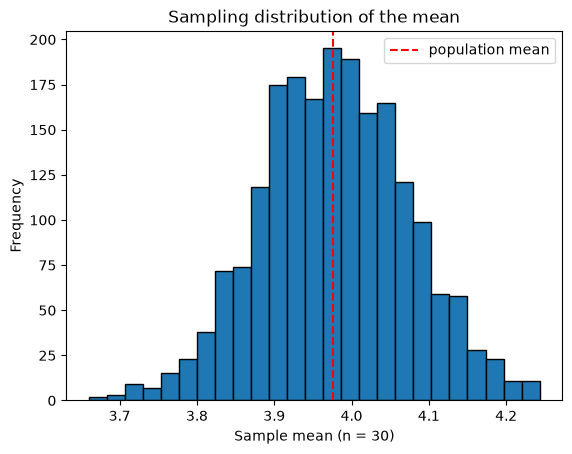

In [13]:
plt.hist(means30, bins=25, edgecolor='black')
plt.axvline(score.mean(), color='red', linestyle='--', label='population mean')
plt.xlabel('Sample mean (n = 30)')
plt.ylabel('Frequency')
plt.title('Sampling distribution of the mean')
plt.legend()
plt.show()

The sample means pile up in a bell shape around the actual mean, and their spread is close to s/√n (the standard error). So even if the scores themselves are not perfectly normal, the mean is approximately normal, which is what justifies using normal / t based intervals and tests below.

## Confidence Intervals for the Mean

Population standard deviation is not known, so the t distribution is used:

CI = x̄ ± t(α/2, n-1) × s/√n

In [14]:
def mean_ci(x, conf=0.95):
    n = len(x)
    xbar = x.mean()
    se = x.std() / np.sqrt(n)
    tcrit = stats.t.ppf((1 + conf) / 2, n - 1)
    return xbar - tcrit * se, xbar + tcrit * se

for name, data in [('All 120 patients', score),
                   ('Random sample (40)', srs['Satisfaction_Score']),
                   ('Stratified sample (40)', strat['Satisfaction_Score'])]:
    lo, hi = mean_ci(data)
    print(f'{name:24s} mean = {data.mean():.4f}   95% CI = ({lo:.4f}, {hi:.4f})')

# cross check with scipy
print()
lo2, hi2 = stats.t.interval(0.95, len(score) - 1, loc=score.mean(), scale=stats.sem(score))
print('scipy check:', round(lo2, 4), round(hi2, 4))

All 120 patients         mean = 3.9758   95% CI = (3.8822, 4.0695)
Random sample (40)       mean = 3.9500   95% CI = (3.7988, 4.1012)
Stratified sample (40)   mean = 3.9575   95% CI = (3.8383, 4.0767)

scipy check: 3.8822 4.0695


In [15]:
rows = []
for h, g in df.groupby('Hospital'):
    lo, hi = mean_ci(g['Satisfaction_Score'])
    rows.append([h, len(g), g['Satisfaction_Score'].mean(), lo, hi])
hosp_ci = pd.DataFrame(rows, columns=['Hospital', 'n', 'mean', 'lower', 'upper']).set_index('Hospital')
hosp_ci.round(4)

,n,mean,lower,upper
Hospital,,,,
A,34,4.0147,3.8568,4.1727
B,42,3.7714,3.6011,3.9417
C,44,4.1409,3.9948,4.2870


In [16]:
rows = []
for a, g in df.groupby('Age_Group'):
    lo, hi = mean_ci(g['Satisfaction_Score'])
    rows.append([a, len(g), g['Satisfaction_Score'].mean(), lo, hi])
age_ci = pd.DataFrame(rows, columns=['Age_Group', 'n', 'mean', 'lower', 'upper']).set_index('Age_Group')
age_ci.round(4)

,n,mean,lower,upper
Age_Group,,,,
18-30,30,3.9133,3.7158,4.1109
31-45,26,4.0769,3.8973,4.2566
46-60,27,3.9481,3.7000,4.1963
60+,37,3.9757,3.8161,4.1353


Effect of the confidence level on the width of the interval (overall mean):

In [17]:
for c in [0.90, 0.95, 0.99]:
    lo, hi = mean_ci(score, c)
    print(f'{int(c*100)}% CI: ({lo:.4f}, {hi:.4f})   width = {hi-lo:.4f}')

90% CI: (3.8974, 4.0542)   width = 0.1568
95% CI: (3.8822, 4.0695)   width = 0.1873
99% CI: (3.8520, 4.0996)   width = 0.2476


Higher confidence gives a wider interval (we pay for being more sure with a less precise range).

### Confidence interval for a proportion

Taking a score of 4 or above as a "satisfied" patient, we can also estimate the proportion of satisfied patients: p̂ ± z × √(p̂(1-p̂)/n)

In [18]:
satisfied = (score >= 4)
n = len(score)
p_hat = satisfied.mean()
se_p = np.sqrt(p_hat * (1 - p_hat) / n)
z95 = stats.norm.ppf(0.975)

print('Satisfied patients:', satisfied.sum(), 'out of', n)
print('p-hat:', round(p_hat, 4))
print(f'95% CI for proportion: ({p_hat - z95 * se_p:.4f}, {p_hat + z95 * se_p:.4f})')

Satisfied patients: 61 out of 120
p-hat: 0.5083
95% CI for proportion: (0.4189, 0.5978)


## Hypothesis Tests

### One sample Z and t test
Suppose the hospitals want the average satisfaction to be 4.0 (this target is our own assumption, it is not given in the data).

- H0: μ = 4.0
- H1: μ ≠ 4.0 (two tailed), α = 0.05

n = 120 is large so Z can be used with s in place of σ; the t-test is the more correct one because σ is unknown, and both should agree here.

In [19]:
mu0 = 4.0
xbar = score.mean()
s = score.std()
n = len(score)

z = (xbar - mu0) / (s / np.sqrt(n))
p_z = 2 * (1 - stats.norm.cdf(abs(z)))
print('Z test : z =', round(z, 4), ' p =', round(p_z, 4))

t_stat, p_t = stats.ttest_1samp(score, mu0)
print('t test : t =', round(t_stat, 4), ' p =', round(p_t, 4))

print()
print('critical z  (+-):', round(stats.norm.ppf(0.975), 3))
print('critical t  (+-):', round(stats.t.ppf(0.975, n - 1), 3))

Z test : z = -0.511  p = 0.6094
t test : t = -0.511  p = 0.6103

critical z  (+-): 1.96
critical t  (+-): 1.98


p-value is much larger than 0.05 (and |t| is below the critical value), so we fail to reject H0. The average satisfaction is not significantly different from 4.0.

### Two sample t test (independent)
Hospital B has the lowest mean and C the highest, so compare these two.

- H0: μB = μC
- H1: μB ≠ μC

Levene's test is checked first for equal variances.

In [20]:
b = df[df['Hospital'] == 'B']['Satisfaction_Score']
c = df[df['Hospital'] == 'C']['Satisfaction_Score']

print('Levene p-value:', round(stats.levene(b, c).pvalue, 4))

t_bc, p_bc = stats.ttest_ind(b, c, equal_var=True)
print('pooled t-test  : t =', round(t_bc, 4), ' p =', round(p_bc, 5))

t_w, p_w = stats.ttest_ind(b, c, equal_var=False)
print('Welch t-test   : t =', round(t_w, 4), ' p =', round(p_w, 5))

Levene p-value: 0.6976
pooled t-test  : t = -3.3337  p = 0.00128
Welch t-test   : t = -3.3237  p = 0.00133


Variances are similar (Levene p > 0.05), and the t-test gives p well below 0.05, so B and C really do differ in mean satisfaction. Welch's version gives the same decision.

Same kind of test for the youngest (18-30) and the oldest (60+) patients:

In [21]:
young = df[df['Age_Group'] == '18-30']['Satisfaction_Score']
old = df[df['Age_Group'] == '60+']['Satisfaction_Score']

print('Levene p-value:', round(stats.levene(young, old).pvalue, 4))
t_yo, p_yo = stats.ttest_ind(young, old, equal_var=True)
print('t =', round(t_yo, 4), ' p =', round(p_yo, 4))

Levene p-value: 0.6653
t = -0.5057  p = 0.6147


p is large, so no evidence that the youngest and oldest patients differ.

### Paired t-test
Not applicable here. A paired test needs two readings on the *same* patient (before / after), but every patient in this survey gave only one score and belongs to just one hospital and one age group, so the groups are independent.

## One-way ANOVA

A t-test only compares two groups, and doing many t-tests increases the chance of a false positive. For 3 hospitals and 4 age groups, one-way ANOVA tests all the group means together.

- H0: all group means are equal
- H1: at least one group mean is different

F = (variation between groups) / (variation within groups)

In [22]:
def my_anova(groups):
    allvals = np.concatenate(groups)
    grand = allvals.mean()
    k = len(groups)
    N = len(allvals)

    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ssw = sum(((g - g.mean()) ** 2).sum() for g in groups)

    msb = ssb / (k - 1)
    msw = ssw / (N - k)
    F = msb / msw
    p = 1 - stats.f.cdf(F, k - 1, N - k)
    eta2 = ssb / (ssb + ssw)
    return ssb, ssw, k - 1, N - k, msb, msw, F, p, eta2

by_hosp = [g['Satisfaction_Score'].values for _, g in df.groupby('Hospital')]
by_age = [g['Satisfaction_Score'].values for _, g in df.groupby('Age_Group')]

for label, grp in [('Hospital', by_hosp), ('Age group', by_age)]:
    ssb, ssw, dfb, dfw, msb, msw, F, p, eta2 = my_anova(grp)
    print(label)
    print(f'  SS between = {ssb:.4f}  (df {dfb})   MS = {msb:.4f}')
    print(f'  SS within  = {ssw:.4f}  (df {dfw})  MS = {msw:.4f}')
    print(f'  F = {F:.4f}   p = {p:.5f}   eta squared = {eta2:.4f}')
    print()

Hospital
  SS between = 3.0052  (df 2)   MS = 1.5026
  SS within  = 28.9347  (df 117)  MS = 0.2473
  F = 6.0759   p = 0.00309   eta squared = 0.0941

Age group
  SS between = 0.4036  (df 3)   MS = 0.1345
  SS within  = 31.5363  (df 116)  MS = 0.2719
  F = 0.4948   p = 0.68657   eta squared = 0.0126



The same thing with scipy's `f_oneway`, to check the hand calculation:

In [23]:
f_hosp, p_hosp = stats.f_oneway(*by_hosp)
f_age, p_age = stats.f_oneway(*by_age)

print('Hospital  : F =', round(f_hosp, 4), ' p =', round(p_hosp, 5))
print('Age group : F =', round(f_age, 4), ' p =', round(p_age, 5))

for name, p in [('Hospital', p_hosp), ('Age group', p_age)]:
    if p < 0.05:
        print(name, '-> reject H0, means are not all equal')
    else:
        print(name, '-> fail to reject H0, no significant difference')

Hospital  : F = 6.0759  p = 0.00309
Age group : F = 0.4948  p = 0.68657
Hospital -> reject H0, means are not all equal
Age group -> fail to reject H0, no significant difference


### Checking the ANOVA assumptions
ANOVA assumes that the groups are independent, roughly normal, and have similar variances. Levene's test is used for equal variance and Shapiro-Wilk for normality inside each group (p > 0.05 means the assumption is okay).

In [24]:
print('Levene (equal variance)')
print('  Hospital  p =', round(stats.levene(*by_hosp).pvalue, 4))
print('  Age group p =', round(stats.levene(*by_age).pvalue, 4))

print()
print('Shapiro-Wilk (normality) per group')
for h, g in df.groupby('Hospital'):
    print('  Hospital', h, 'p =', round(stats.shapiro(g['Satisfaction_Score']).pvalue, 4))
for a, g in df.groupby('Age_Group'):
    print('  Age', a, 'p =', round(stats.shapiro(g['Satisfaction_Score']).pvalue, 4))

Levene (equal variance)
  Hospital  p = 0.7599
  Age group p = 0.6174

Shapiro-Wilk (normality) per group
  Hospital A p = 0.7967
  Hospital B p = 0.647
  Hospital C p = 0.1705
  Age 18-30 p = 0.5843
  Age 31-45 p = 0.7645
  Age 46-60 p = 0.4177
  Age 60+ p = 0.2508


All the p-values are above 0.05, so the equal variance and normality assumptions are reasonable and the ANOVA results can be trusted.

### Post-hoc test (Tukey HSD)
Only the hospital ANOVA was significant, but ANOVA does not say *which* hospitals differ. Tukey's HSD compares every pair while keeping the overall error rate at 5%.

In [25]:
hosp_names = sorted(df['Hospital'].unique())
tk = stats.tukey_hsd(*by_hosp)
ci = tk.confidence_interval(0.95)

print('pair   mean diff   p-value    95% CI')
for i in range(len(hosp_names)):
    for j in range(i + 1, len(hosp_names)):
        diff = by_hosp[i].mean() - by_hosp[j].mean()
        print(f'{hosp_names[i]} - {hosp_names[j]}   {diff:8.4f}   {tk.pvalue[i, j]:.4f}   ({ci.low[i, j]:.4f}, {ci.high[i, j]:.4f})')

pair   mean diff   p-value    95% CI
A - B     0.2433   0.0901   (-0.0291, 0.5156)
A - C    -0.1262   0.5090   (-0.3958, 0.1434)
B - C    -0.3695   0.0023   (-0.6242, -0.1148)


Only B vs C is significant (its interval does not contain 0). A vs B and A vs C are not significant on their own.

## Visualization

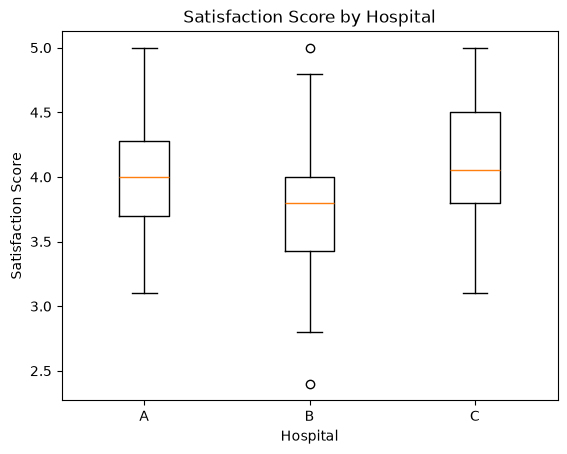

In [26]:
groups = [g['Satisfaction_Score'].values for _, g in df.groupby('Hospital')]
plt.boxplot(groups, tick_labels=hosp_names)
plt.xlabel('Hospital')
plt.ylabel('Satisfaction Score')
plt.title('Satisfaction Score by Hospital')
plt.show()

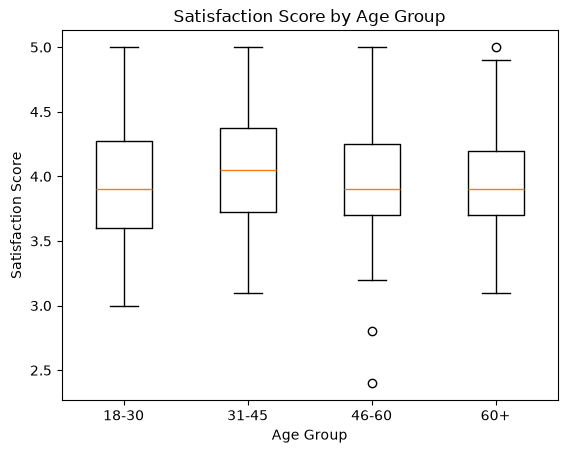

In [27]:
age_names = sorted(df['Age_Group'].unique())
plt.boxplot(by_age, tick_labels=age_names)
plt.xlabel('Age Group')
plt.ylabel('Satisfaction Score')
plt.title('Satisfaction Score by Age Group')
plt.show()

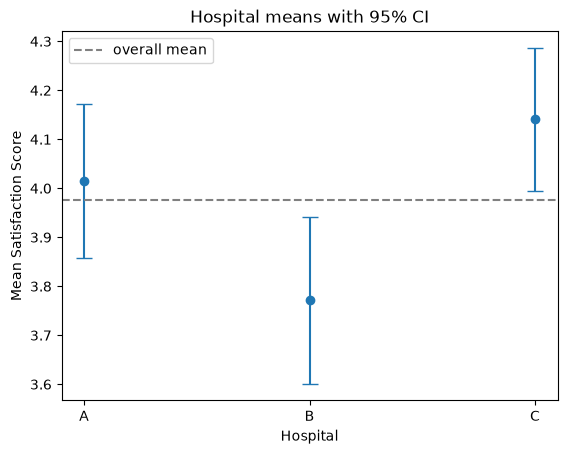

In [28]:
err = (hosp_ci['upper'] - hosp_ci['lower']) / 2
plt.errorbar(hosp_ci.index, hosp_ci['mean'], yerr=err, fmt='o', capsize=6)
plt.axhline(score.mean(), color='gray', linestyle='--', label='overall mean')
plt.xlabel('Hospital')
plt.ylabel('Mean Satisfaction Score')
plt.title('Hospital means with 95% CI')
plt.legend()
plt.show()

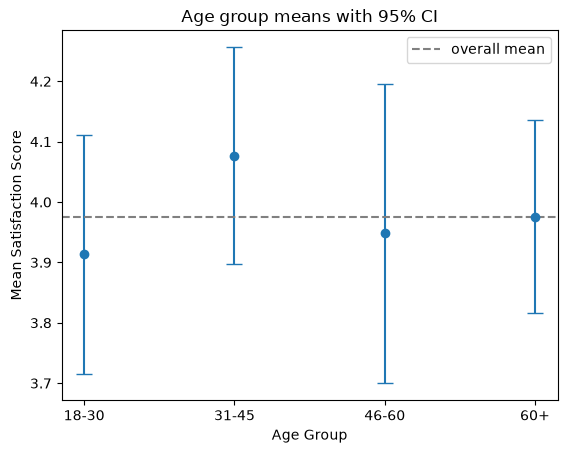

In [29]:
err = (age_ci['upper'] - age_ci['lower']) / 2
plt.errorbar(age_ci.index, age_ci['mean'], yerr=err, fmt='o', capsize=6)
plt.axhline(score.mean(), color='gray', linestyle='--', label='overall mean')
plt.xlabel('Age Group')
plt.ylabel('Mean Satisfaction Score')
plt.title('Age group means with 95% CI')
plt.legend()
plt.show()

## Observations

- The survey has 120 patients (A: 34, B: 42, C: 44) with an overall mean satisfaction of about 3.98 and a standard deviation of about 0.52. The data was clean, so no rows were removed.
- Random and stratified samples of 40 gave means of 3.95 and 3.96, both close to the full-data mean, so both are reasonable samples. The sampling distribution of the mean (n = 30) was bell shaped with a spread of 0.095, almost the same as s/√n = 0.095 (CLT).
- The 95% CI for the overall mean satisfaction is (3.88, 4.07). Increasing the confidence to 99% widens it to (3.85, 4.10).
- Hospital C has the highest mean (4.14, CI 3.99 to 4.29), then A (4.01) and B has the lowest (3.77, CI 3.60 to 3.94). The CIs of B and C only just touch, while the age group CIs overlap almost completely.
- About 51% of patients scored 4 or above (95% CI 42% to 60%).
- One sample Z / t test against 4.0: p = 0.61, so the overall mean is not significantly different from 4.0.
- Two sample t-test B vs C: t = -3.33, p = 0.0013, significant. 18-30 vs 60+: p = 0.61, not significant. A paired test could not be used since the groups are independent.
- One-way ANOVA across hospitals: F = 6.08, p = 0.0031 < 0.05, so reject H0. Across age groups: F = 0.49, p = 0.687, so fail to reject H0.
- Levene's and Shapiro-Wilk p-values were all above 0.05, so the ANOVA assumptions hold.
- Tukey HSD shows that only B vs C differs significantly (p = 0.0023). A vs B (p = 0.090) and A vs C (p = 0.509) are not significant.
- Eta squared is 0.094 for hospital and 0.013 for age group, so hospital explains about 9% of the variation in scores. That is a small to medium effect, most of the variation is between individual patients.

## Conclusion

The survey data of 120 patients was analysed with samples, confidence intervals, hypothesis tests and one-way ANOVA. The mean patient satisfaction is about 3.98 and we are 95% confident that the true mean for all patients lies between 3.88 and 4.07. This is not significantly different from a target of 4.0 (p = 0.61).

Satisfaction differs significantly between hospitals (ANOVA F = 6.08, p = 0.0031). The Tukey test shows that this comes from Hospital B (lowest, 3.77) being lower than Hospital C (highest, 4.14), while Hospital A is not significantly different from either. Satisfaction does not differ significantly between age groups (F = 0.49, p = 0.687), so the small differences between age groups can be put down to chance.

The assumptions of ANOVA (normality and equal variance) were satisfied. Since this is survey data and not an experiment, the results only show that Hospital B scores lower, they do not show the reason, so the service at Hospital B would be worth looking into. The sample is also small (120) and the groups are not of equal size, so the results should be taken with that limit in mind.